### Иерархическая кластеризация — это метод кластеризации, который создает деревоподобную структуру кластеров (дендрограмму). В отличие от K-Means, где вы заранее задаете число кластеров, иерархическая кластеризация позволяет анализировать разное число кластеров и выбирать оптимальное разбиение.

Существуют два подхода к иерархической кластеризации:

Агломеративная кластеризация (снизу вверх, bottom-up).
Этот метод начинает с того, что каждая точка — отдельный кластер. Находим две ближайшие точки (или кластера). Объединяем их в один кластер. Повторяем процесс, пока все точки не объединятся в один кластер.
Ее преимущество — позволяет легко определить оптимальное число кластеров. Недостаток — вычислительно дорогостоящий (работает медленнее K-Means).
Дивизивная кластеризация (сверху вниз, top-down).
Этот метод начинает с одного большого кластера, содержащего все точки. Затем — разбивает его на два подмножества. Повторяет процесс разбиения до тех пор, пока каждый кластер не станет отдельной точкой.
Её преимущество — может лучше справляться с нестандартными структурами данных. Недостаток — требует больше вычислений, чем агломеративный метод.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_10.png)

Давайте рассмотрим на практике реализацию и подробнее обсудим теоретические основы иерархической кластеризации:

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\IDE\2 семестр\Классическое МО\Модуль 7. Кластеризация\df.k_means\Country-data.csv")

# Создадим вектор признаков
X = df.iloc[:, 1:]

Для начала найдем и визуализируем денрограмму для агломеративной иерархической кластеризации:

Дендрограмма— это древовидная структура, отображающая процесс объединения или разбиения кластеров.

Важные моменты:

Чем выше соединение на оси Y, тем дальше кластеры друг от друга.
Обрезая дендрограмму на определенном уровне, можно выбрать оптимальное число кластеров.

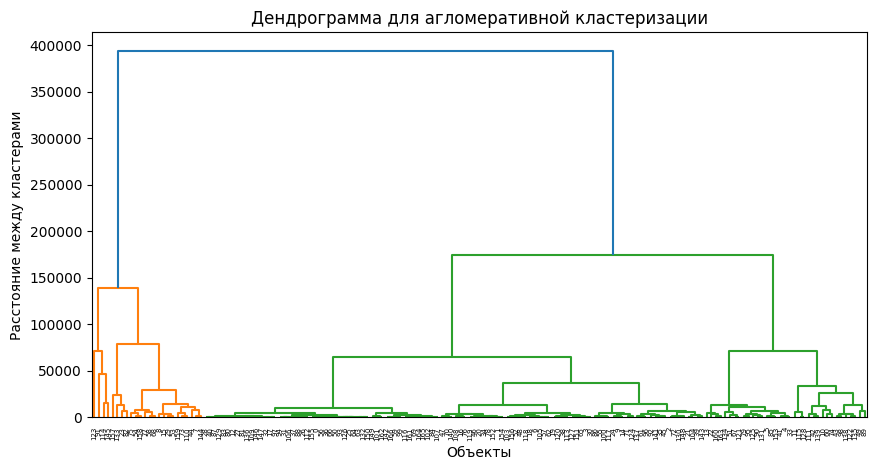

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Строим матрицу расстояний (linkage matrix)
Z = linkage(X, method="ward")  # Метод Уорда для минимизации дисперсии

# Строим дендрограмму
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Дендрограмма для агломеративной кластеризации")
plt.xlabel("Объекты")
plt.ylabel("Расстояние между кластерами")
plt.show()

Разберем по порядку:

Функция scipy.cluster.hierarchy.linkage() выполняет иерархическую агломеративную кластеризацию, создавая матрицу связи (linkage matrix), которая показывает, как кластеры объединяются на каждом шаге. Чаще всего этот метод используют для визуализации иерархии кластеризации в виде дендрограммы:

In [ ]:
scipy.cluster.hierarchy.linkage(X, method='single', metric='euclidean', optimal_ordering=False)

 — вектор признаков наших данных.

method — метод объединения кластеров. Этот параметр определяет, как рассчитывается расстояние между новым кластером (получившимся после объединения) и оставшимися кластерами.

method	Описание	Подходит для
single	Минимальное расстояние между точками кластеров	Вытянутые и разреженные кластеры
complete	Максимальное расстояние между точками кластеров	Компактные кластеры
average	Среднее расстояние между точками кластеров	Сбалансированные кластеры
ward	Минимизирует разброс внутри кластеров (минимизирует дисперсию)	Компактные, равномерные кластеры
![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_11.png)


metric – метрика расстояния (euclidean, manhattan, cosine). Определяет, как измеряется расстояние между точками.

Метод:

Z = linkage(X, method="ward")
Если в данных  объектов, то метод возвращает  матрицу расстояний для всех этапов объединения в агломеративной иерархической кластеризации:

Первая колонка отвечает за индекс первого объединяемого кластера (или объекта на первом шаге).
Вторая колонка отвечает за индекс второго объединяемого кластера (или объекта на первом шаге).
Третья колонка отвечает за расстояние между объединяемыми кластерами (или объектами на первых шагах).
Четвертая колонка — число точек в новом кластере.
Для датасета первые две строчки матрицы расстояния выглядят следующим образом:

array([[25.        , 64.        , 49.61507432,  2.        ],
       [ 0.        , 56.        , 54.68805903,  2.        ]])
Объекты с индексами 25 и 64 объединяются, так как между ними расстояние 49.615. В новом кластере теперь 2 точки.
Объединяются объекты с индексами 0 и 56, расстояние 54.688. В новом кластере тоже 2 точки.
Посмотрим как выглядит строка 105 в нашей матрице:

array([ 243. , 244. , 2104.82659391, 10. ])
На 105 шаге алгоритм объединяет два кластера: кластер с индексом 243 и кластер с индексом 244. Эти два кластера находятся на расстоянии 2104.83 (в методе ward — это разница в дисперсиях). В новом объединенном кластере теперь 10 точек — значит, оба объединяемых кластера были уже составными.

Теперь давайте разберем подробнее полученную дендрограмму:

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_12.png)

Структура дендрограммы:

Ось X — объекты из выборки (страны, товары, пользователи и пр.).
Ось Y — расстояние (или мера сходства), на котором сливаются кластеры.
Линии (ветви) — показывают, какие объекты и на каком уровне объединяются в кластеры.
Высота соединений — чем выше линия слияния, тем более различны объединяемые кластеры.
Как читать дендрограмму?

Низкие слияния (маленькая высота) означают, что объекты похожи друг на друга.
Высокие слияния (большая высота) указывают, что объединяемые группы довольно разные.
Если отсечь дерево на определенном уровне, можно получить желаемое число кластеров.
Как выбрать оптимальное число кластеров?

Метод горизонтального разреза.

Выберите уровень, на котором разрезаете дендрограмму (обычно там, где большое расстояние между уровнями объединения). Число кластеров равно числу оставшихся ветвей после разреза.

Метод «плеча» (Elbow Method).

Ищем самый большой разрыв по высоте слияния. Количество кластеров равно число ветвей ниже разрыва.

Чем выше уровень объединения, тем разнообразнее кластеры. Оптимальное число кластеров выбирается так, чтобы внутри кластера объекты были похожи, а между кластерами различались.
Допустим, вы остановились на четырех кластерах исходя из дендрограммы. Теперь для кластеризации воспользуемся алгоритмом агломеративной иерархической кластеризации из библиотеки sklearn:

In [4]:
# Применяем агломеративную кластеризацию
agg_clustering = AgglomerativeClustering(n_clusters=5, linkage="ward")
clusters = agg_clustering.fit_predict(X)

Обратите внимание, что здесь в гиперпараметр linkage необходимо указывать тот же метод, что и использовали для построения дендрограммы.
Z = linkage(X, method="ward")
Можно также воспользоваться и методом fcluster из библитеки SciPy (scipy.cluster.hierarchy).

Таким образом, иерархическая кластеризация — это хороший инструмент анализа данных, который позволяет находить группы схожих объектов без необходимости заранее задавать число кластеров.

Плюсы
Позволяет визуально изучить структуру данных с помощью дендрограммы.
Работает без необходимости заранее задавать число кластеров.
Хорошо подходит для небольших и средних объемов данных.
Минусы
Плохо масштабируется на большие данные (сложность O(n²)).
Требует выбора метода объединения и метрики расстояния, что может повлиять на результат.
Не всегда хорошо работает с кластерами сложной формы.
Когда использовать?

Когда нужно понять структуру данных.
Для небольших наборов данных, где важна интерпретация.
Если важна визуализация взаимосвязей объектов.